In [1]:
import os
import glob
import xarray as xr
import rioxarray
import pandas as pd

folder_path = "mystorage/CH4_Mensual"

file_paths = sorted(glob.glob(os.path.join(folder_path, "CH4_*.tiff")))

data_arrays = []
time_coords = []

print(f"Construyendo el Data Cube de CH4 a partir de {len(file_paths)} matrices...")

for file_path in file_paths:
    filename = os.path.basename(file_path)
    
    parts = filename.replace(".tiff", "").split("_")
    year = int(parts[1])
    month = int(parts[2])
    
    date = pd.Timestamp(year=year, month=month, day=1)
    time_coords.append(date)
    
    da_raw = rioxarray.open_rasterio(file_path)
    
    ch4_band = da_raw.sel(band=1, drop=True)
    mask_band = da_raw.sel(band=2, drop=True)
    
    da_clean = ch4_band.where(mask_band == 1)
    
    data_arrays.append(da_clean)


ch4_cube = xr.concat(data_arrays, dim=pd.Index(time_coords, name="time"))

ch4_cube.name = "CH4"
ch4_cube.attrs["units"] = "ppb"
ch4_cube.attrs["long_name"] = "Fracción molar de aire seco promediada en la columna de CH4"
ch4_cube.rio.write_crs("EPSG:4326", inplace=True)

print("Data Cube de CH4 construido")
ch4_cube

Construyendo el Data Cube de CH4 a partir de 84 matrices...


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as 

Data Cube de CH4 construido


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


<xarray.DataArray 'CH4' (time: 84, y: 14, x: 9)> Size: 42kB
array([[[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        ...,
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]],

       [[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
...
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]],

       [[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        ...,
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]]], shape=(84, 14, 9), dtype=float32)
Coordinates:
  * time         (time) datetime64[us] 672B 2018-07-01 2018-08-01 ... 2025-06-01
  * y            (y) float64 112B 14.89 14.84 14.79 14.75 ... 14.36 14.31 14.27
  * x            (x) float64 72B -90.73 -90.67 -90.61 ... -90.36 -90.3 -90.24
    spatial_ref  int64 8B 0
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:           Area
    scale_factor:            1.0
    add_offset:              0.0
    units:                   ppb
    long_name:               Fracción molar de aire seco promediada en la col...

In [2]:
import geopandas as gpd

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson")

poligono_amg = poligono_amg.to_crs("EPSG:4326")

print("Aplicando enmascaramiento espacial al Cubo de Datos...")

ch4_cube_masked = ch4_cube.rio.clip(poligono_amg.geometry, poligono_amg.crs, drop=False)

print("Enmascaramiento completado")

ch4_cube_masked

Aplicando enmascaramiento espacial al Cubo de Datos...
Enmascaramiento completado


<xarray.DataArray 'CH4' (time: 84, y: 14, x: 9)> Size: 42kB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]],
      shape=(84, 14, 9), dtype=float32)
Coordinates:
  * time         (time) datetime64[us] 672B 2018-07-01 2018-08-01 ... 2025-06-01
  * y            (y) float64 112B 14.89 14.84 14.79 14.75 ... 14.36 14.31 14.27
  * x            (x) float64 72B -90.73 -90.67 -90.61 ... -90.36 -90.3 -90.24
    spatial_ref  int64 8B 0
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:           Area
    scale_factor:            1.0
    add_offset:              0.0
    units:                   ppb
    long_name:               Fracción molar de aire seco promediada en la col...

In [3]:
ch4_cube_masked.to_netcdf("Cubo_CH4_Final.nc")

In [4]:
ch4_linea_base = ch4_cube_masked.mean(dim="time", skipna=True)

print("Línea Base Histórica de CH4 calculada")

ch4_linea_base.to_netcdf("Linea_Base_CH4_AMG.nc")
print("Archivo guardado físicamente como 'Linea_Base_CH4_AMG.nc'")


Línea Base Histórica de CH4 calculada
Archivo guardado físicamente como 'Linea_Base_CH4_AMG.nc'


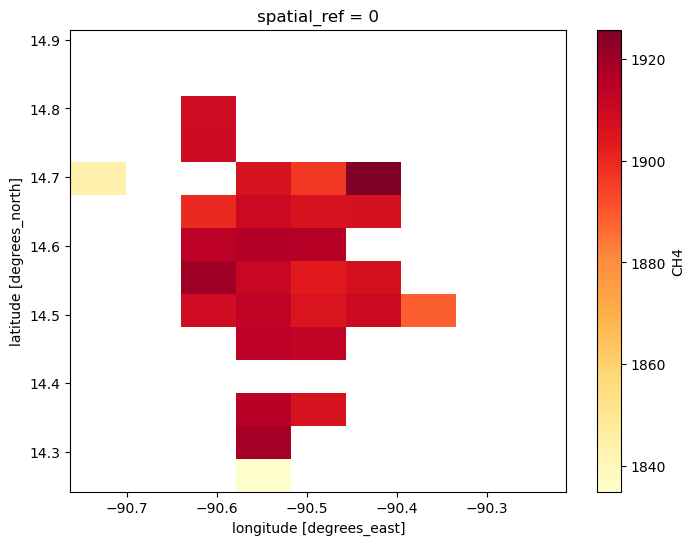

In [5]:
ch4_linea_base.plot(cmap="YlOrRd", size=6)

In [6]:
max_ch4_val = ch4_linea_base.max()

hotspot_ch4 = ch4_linea_base.where(ch4_linea_base == max_ch4_val, drop=True)

latitud_ch4 = hotspot_ch4.y.values[0]
longitud_ch4 = hotspot_ch4.x.values[0]
concentracion_max_ch4 = hotspot_ch4.values[0][0]

print("Hotspot Histórico de CH4 (2018-2025)")
print(f"Latitud : {latitud_ch4}")
print(f"Longitud: {longitud_ch4}")
print(f"Valor   : {concentracion_max_ch4} ppb")

Hotspot Histórico de CH4 (2018-2025)
Latitud : 14.698568186785714
Longitud: -90.42605087666666
Valor   : 1925.77099609375 ppb
